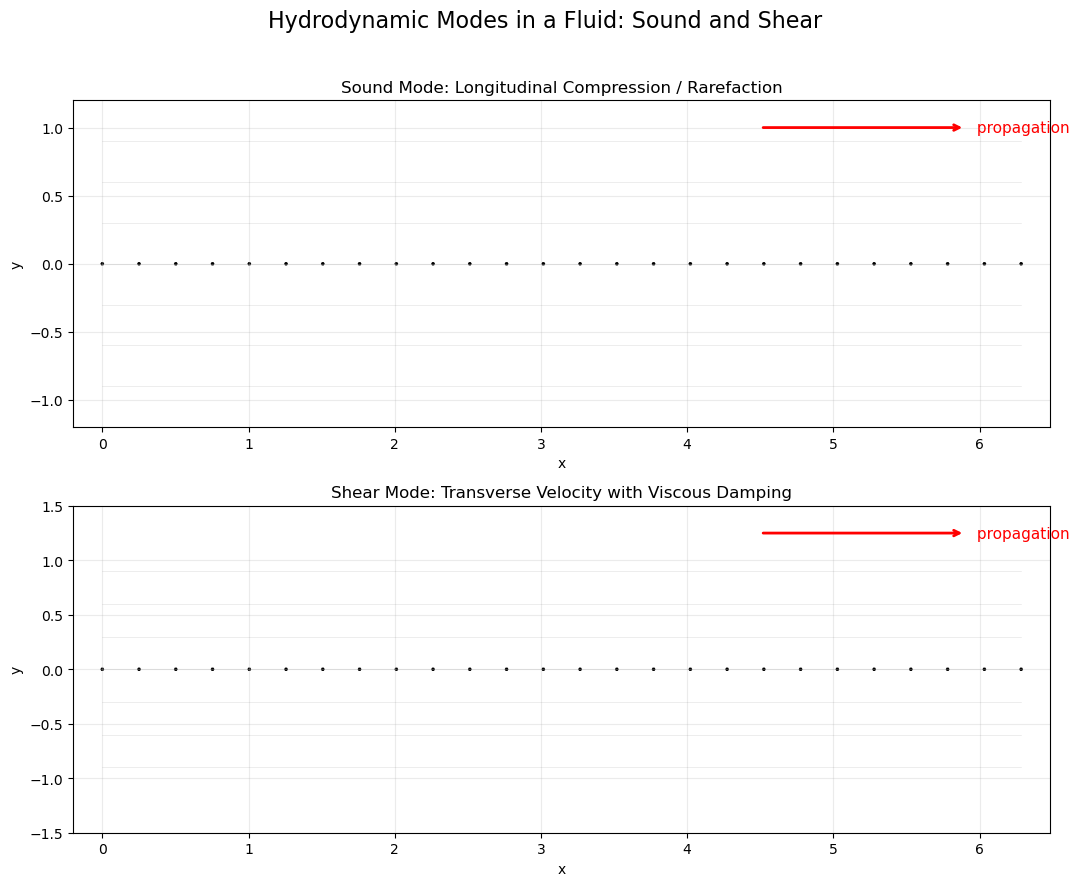

MovieWriter ffmpeg unavailable; using Pillow instead.


ValueError: unknown file extension: .mp4

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

# ============================================================
# Parameters
# ============================================================
Lx = 2 * np.pi
Nx = 26
Ny = 7

x0 = np.linspace(0, Lx, Nx)
y0 = np.linspace(-0.9, 0.9, Ny)
X0, Y0 = np.meshgrid(x0, y0)

# Wave / hydro parameters
A_sound = 0.18        # longitudinal displacement amplitude
A_shear = 0.22        # transverse displacement amplitude

k_sound = 1.0         # sound wave number
k_shear = 1.0         # shear wave number

cs = 1.2              # sound speed (sets omega_sound = cs*k)
omega_sound = cs * k_sound

nu = 0.12             # kinematic viscosity-like parameter
gamma_shear = nu * k_shear**2   # shear diffusive damping
gamma_sound = 0.03              # weak damping of sound

# animation timing
fps = 30
T = 14
nframes = fps * T
dt = 0.05

# ============================================================
# Figure setup
# ============================================================
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 9))
fig.suptitle("Hydrodynamic Modes in a Fluid: Sound and Shear", fontsize=16)

# -------------------------
# Sound mode panel
# -------------------------
ax1.set_title("Sound Mode: Longitudinal Compression / Rarefaction")
ax1.set_xlim(-0.2, Lx + 0.2)
ax1.set_ylim(-1.2, 1.2)
ax1.set_xlabel("x")
ax1.set_ylabel("y")
ax1.grid(alpha=0.25)

# Equilibrium guide lines
for yy in y0:
    ax1.plot([0, Lx], [yy, yy], color='gray', lw=0.4, alpha=0.25)

sound_scatter = ax1.scatter([], [], s=28, c=[], cmap='coolwarm', vmin=-1, vmax=1)
sound_text = ax1.text(
    0.02, 0.93, "", transform=ax1.transAxes,
    fontsize=11, bbox=dict(boxstyle="round", fc="white", ec="0.7", alpha=0.9)
)

ax1.annotate(
    '', xy=(5.9, 1.0), xytext=(4.5, 1.0),
    arrowprops=dict(arrowstyle='->', lw=2, color='red')
)
ax1.text(5.95, 1.0, " propagation", color='red', va='center', fontsize=11)

# -------------------------
# Shear mode panel
# -------------------------
ax2.set_title("Shear Mode: Transverse Velocity with Viscous Damping")
ax2.set_xlim(-0.2, Lx + 0.2)
ax2.set_ylim(-1.5, 1.5)
ax2.set_xlabel("x")
ax2.set_ylabel("y")
ax2.grid(alpha=0.25)

for yy in y0:
    ax2.plot([0, Lx], [yy, yy], color='gray', lw=0.4, alpha=0.25)

shear_scatter = ax2.scatter([], [], s=28, c='seagreen')
shear_text = ax2.text(
    0.02, 0.93, "", transform=ax2.transAxes,
    fontsize=11, bbox=dict(boxstyle="round", fc="white", ec="0.7", alpha=0.9)
)

ax2.annotate(
    '', xy=(5.9, 1.25), xytext=(4.5, 1.25),
    arrowprops=dict(arrowstyle='->', lw=2, color='red')
)
ax2.text(5.95, 1.25, " propagation", color='red', va='center', fontsize=11)

# Optional velocity arrows on one central row to highlight direction
mid_row = Ny // 2
x_ar = X0[mid_row]
y_ar_sound = Y0[mid_row]
y_ar_shear = Y0[mid_row]

sound_quiver = ax1.quiver(
    x_ar, y_ar_sound,
    np.zeros_like(x_ar), np.zeros_like(x_ar),
    angles='xy', scale_units='xy', scale=1.8,
    color='black', width=0.004
)

shear_quiver = ax2.quiver(
    x_ar, y_ar_shear,
    np.zeros_like(x_ar), np.zeros_like(x_ar),
    angles='xy', scale_units='xy', scale=1.8,
    color='black', width=0.004
)

# ============================================================
# Physics model
# ============================================================
def sound_mode_positions(t):
    """
    Longitudinal displacement field:
        xi_x(x,t) = A exp(-gamma t) cos(kx - wt)
    Velocity:
        v_x = d xi_x / dt = A exp(-gamma t) [w sin(kx-wt) - gamma cos(kx-wt)]
    Density fluctuation (linearized, schematic):
        delta rho ~ - d(xi_x)/dx ~ k A exp(-gamma t) sin(kx - wt)
    """
    phase = k_sound * X0 - omega_sound * t
    decay = np.exp(-gamma_sound * t)

    xi_x = A_sound * decay * np.cos(phase)
    X = X0 + xi_x
    Y = Y0.copy()

    vx = A_sound * decay * (
        omega_sound * np.sin(phase) - gamma_sound * np.cos(phase)
    )

    # schematic density fluctuation
    drho = k_sound * A_sound * decay * np.sin(phase)

    return X, Y, vx, drho


def shear_mode_positions(t):
    """
    Transverse shear mode:
        xi_y(x,t) = A exp(-gamma t) cos(kx - wt)
    In strict hydrodynamics, shear is diffusive:
        omega = -i nu k^2
    so there is decay without true propagation.
    
    To make it visually intuitive, we allow a weak traveling phase.
    If you want pure diffusion, set omega_shear = 0.
    """
    omega_shear = 0.6   # set to 0.0 for purely diffusive-looking shear
    phase = k_shear * X0 - omega_shear * t
    decay = np.exp(-gamma_shear * t)

    xi_y = A_shear * decay * np.cos(phase)
    X = X0.copy()
    Y = Y0 + xi_y

    vy = A_shear * decay * (
        omega_shear * np.sin(phase) - gamma_shear * np.cos(phase)
    )

    return X, Y, vy, decay


# ============================================================
# Initialization
# ============================================================
def init():
    Xs, Ys, vxs, drho = sound_mode_positions(0.0)
    sound_scatter.set_offsets(np.c_[Xs.ravel(), Ys.ravel()])
    sound_scatter.set_array(drho.ravel())

    Xh, Yh, vyh, decay = shear_mode_positions(0.0)
    shear_scatter.set_offsets(np.c_[Xh.ravel(), Yh.ravel()])

    sound_quiver.set_UVC(vxs[mid_row], np.zeros_like(vxs[mid_row]))
    shear_quiver.set_UVC(np.zeros_like(vyh[mid_row]), vyh[mid_row])

    sound_text.set_text("Sound: longitudinal motion, density oscillation")
    shear_text.set_text("Shear: transverse motion, viscous decay")

    return (
        sound_scatter, shear_scatter,
        sound_quiver, shear_quiver,
        sound_text, shear_text
    )


# ============================================================
# Animation update
# ============================================================
def update(frame):
    t = frame * dt

    # ---- Sound mode
    Xs, Ys, vxs, drho = sound_mode_positions(t)
    sound_scatter.set_offsets(np.c_[Xs.ravel(), Ys.ravel()])
    sound_scatter.set_array(drho.ravel())
    sound_quiver.set_UVC(vxs[mid_row], np.zeros_like(vxs[mid_row]))

    sound_text.set_text(
        f"Sound mode\n"
        f"$\\omega \\approx c_s k = {omega_sound:.2f}$,  "
        f"damping = {gamma_sound:.2f}\n"
        f"Compression = red, rarefaction = blue"
    )

    # ---- Shear mode
    Xh, Yh, vyh, decay = shear_mode_positions(t)
    shear_scatter.set_offsets(np.c_[Xh.ravel(), Yh.ravel()])
    shear_quiver.set_UVC(np.zeros_like(vyh[mid_row]), vyh[mid_row])

    shear_text.set_text(
        f"Shear mode\n"
        f"$\\gamma_\\eta = \\nu k^2 = {gamma_shear:.3f}$,  "
        f"amplitude ~ $e^{{-\\gamma_\\eta t}}$\n"
        f"Current decay factor = {decay:.3f}"
    )

    return (
        sound_scatter, shear_scatter,
        sound_quiver, shear_quiver,
        sound_text, shear_text
    )


# ============================================================
# Animate
# ============================================================
anim = FuncAnimation(
    fig, update, init_func=init,
    frames=nframes, interval=1000/fps, blit=False
)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

# To save:
anim.save("hydro_sound_shear_particles.gif", writer="pillow", fps=fps)
anim.save("hydro_sound_shear_particles.mp4", writer="ffmpeg", fps=fps)

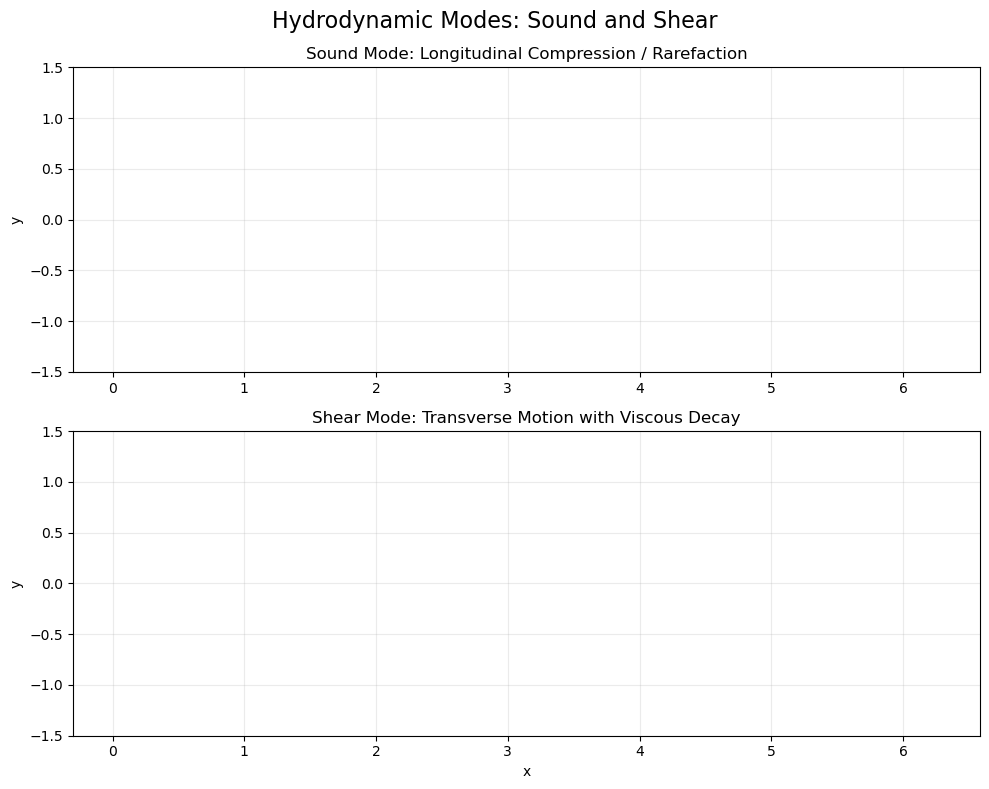

Saved animation to hydro_modes.gif


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter

# ============================================================
# Parameters
# ============================================================
Lx = 2 * np.pi
Nx = 30
Ny = 7

x0 = np.linspace(0, Lx, Nx)
y0 = np.linspace(-0.9, 0.9, Ny)
X0, Y0 = np.meshgrid(x0, y0)

A_sound = 0.18
A_shear = 0.22

k_sound = 1.0
k_shear = 1.0

cs = 1.2
omega_sound = cs * k_sound

nu = 0.12
gamma_shear = nu * k_shear**2
gamma_sound = 0.03

omega_shear = 0.6   # set 0.0 for purely diffusive shear

fps = 25
T = 10
nframes = fps * T
dt = 0.06

# ============================================================
# Figure setup
# ============================================================
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))
fig.suptitle("Hydrodynamic Modes: Sound and Shear", fontsize=16)

for ax in (ax1, ax2):
    ax.set_xlim(-0.3, Lx + 0.3)
    ax.set_ylim(-1.5, 1.5)
    ax.grid(alpha=0.25)

ax1.set_title("Sound Mode: Longitudinal Compression / Rarefaction")
ax2.set_title("Shear Mode: Transverse Motion with Viscous Decay")
ax1.set_ylabel("y")
ax2.set_ylabel("y")
ax2.set_xlabel("x")

sound_scatter = ax1.scatter([], [], s=25, c=[], cmap="coolwarm", vmin=-0.2, vmax=0.2)
shear_scatter = ax2.scatter([], [], s=25, color="seagreen")

# ============================================================
# Physics
# ============================================================
def sound_mode(t):
    phase = k_sound * X0 - omega_sound * t
    decay = np.exp(-gamma_sound * t)

    xi_x = A_sound * decay * np.cos(phase)
    X = X0 + xi_x
    Y = Y0

    drho = k_sound * A_sound * decay * np.sin(phase)
    return X, Y, drho


def shear_mode(t):
    phase = k_shear * X0 - omega_shear * t
    decay = np.exp(-gamma_shear * t)

    xi_y = A_shear * decay * np.cos(phase)
    X = X0
    Y = Y0 + xi_y
    return X, Y


# ============================================================
# Init and update
# ============================================================
def init():
    Xs, Ys, drho = sound_mode(0)
    sound_scatter.set_offsets(np.column_stack([Xs.ravel(), Ys.ravel()]))
    sound_scatter.set_array(drho.ravel())

    Xh, Yh = shear_mode(0)
    shear_scatter.set_offsets(np.column_stack([Xh.ravel(), Yh.ravel()]))

    return sound_scatter, shear_scatter


def update(frame):
    t = frame * dt

    Xs, Ys, drho = sound_mode(t)
    sound_scatter.set_offsets(np.column_stack([Xs.ravel(), Ys.ravel()]))
    sound_scatter.set_array(drho.ravel())

    Xh, Yh = shear_mode(t)
    shear_scatter.set_offsets(np.column_stack([Xh.ravel(), Yh.ravel()]))

    return sound_scatter, shear_scatter


anim = FuncAnimation(
    fig, update, init_func=init,
    frames=nframes, interval=1000/fps, blit=False
)

plt.tight_layout()

# Show window if interactive backend exists
plt.show()

# Save as GIF (this always helps if live display fails)
anim.save("hydro_modes.gif", writer=PillowWriter(fps=fps))
print("Saved animation to hydro_modes.gif")
